# 🩺 Machine Learning Pipeline for Disease Prediction from Medical Data
## CodeAlpha Internship — Task: Disease Prediction from Medical Data

### 1. Library Imports & Environment Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

In [3]:
plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")

### 2. Loading Medical Datasets

In [4]:
dataset = pd.read_csv('dataset.csv')
severity = pd.read_csv('Symptom-severity.csv')
description = pd.read_csv('symptom_Description.csv')
precaution = pd.read_csv('symptom_precaution.csv')

### 3. Data Cleaning & String Standardization

In [5]:
severity['Symptom_clean'] = severity['Symptom'].str.strip().str.replace(' ', '')
severity_map = dict(zip(severity['Symptom_clean'], severity['weight']))

In [6]:
for col in dataset.columns:
    dataset[col] = dataset[col].astype(str).str.strip().str.replace(' ', '')
    dataset[col] = dataset[col].replace('nan', np.nan)

### 4. Binary Feature Matrix Construction

In [7]:
all_symptoms = sorted(list(set(severity['Symptom_clean'].unique())))
symptom_cols = [c for c in dataset.columns if c != 'Disease']

In [8]:
X_binary = pd.DataFrame(0, index=np.arange(len(dataset)), columns=all_symptoms)
for idx, row in dataset.iterrows():
    row_symptoms = [s for s in row[symptom_cols] if pd.notna(s)]
    for s in row_symptoms:
        if s in X_binary.columns:
            X_binary.loc[idx, s] = 1

In [9]:
y = dataset['Disease']

In [10]:
print(f"Binary Feature Matrix Shape: {X_binary.shape}")
print(f"Target Vector Shape:         {y.shape}")

Binary Feature Matrix Shape: (4920, 132)
Target Vector Shape:         (4920,)


### 5. Stratified Train-Test Dataset Splitting

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_binary, y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
print(f"Train Split Shape: {X_train.shape}")
print(f"Test Split Shape:  {X_test.shape}")

Train Split Shape: (3936, 132)
Test Split Shape:  (984, 132)


### 6. Model 1: Decision Tree Classifier

In [13]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [14]:
dt_preds = dt_model.predict(X_test)
dt_acc = accuracy_score(y_test, dt_preds)
print(f"Decision Tree Test Accuracy: {dt_acc * 100:.2f}%")

Decision Tree Test Accuracy: 100.00%


### 7. Model 2: Random Forest Classifier

In [15]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [16]:
rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)
print(f"Random Forest Test Accuracy: {rf_acc * 100:.2f}%")

Random Forest Test Accuracy: 100.00%


### 8. Model 3: Support Vector Classifier (SVM)

In [17]:
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [18]:
svm_preds = svm_model.predict(X_test)
svm_acc = accuracy_score(y_test, svm_preds)
print(f"SVM Test Accuracy: {svm_acc * 100:.2f}%")

SVM Test Accuracy: 100.00%


### 9. Model 4: Gradient Boosting Classifier

In [19]:
gb_model = GradientBoostingClassifier(n_estimators=50, random_state=42)
gb_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (imp

In [20]:
gb_preds = gb_model.predict(X_test)
gb_acc = accuracy_score(y_test, gb_preds)
print(f"Gradient Boosting Test Accuracy: {gb_acc * 100:.2f}%")

Gradient Boosting Test Accuracy: 100.00%


### 10. Multi-Model Performance Benchmarking

In [21]:
models_dict = {
    'Decision Tree': dt_preds,
    'Random Forest': rf_preds,
    'SVM': svm_preds,
    'Gradient Boosting': gb_preds
}

In [22]:
benchmark_list = []
for model_name, preds in models_dict.items():
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='weighted')
    benchmark_list.append({
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })
benchmark_df = pd.DataFrame(benchmark_list)
benchmark_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0
3,Gradient Boosting,1.0,1.0,1.0,1.0


### 11. Model Accuracy Benchmark Visualization

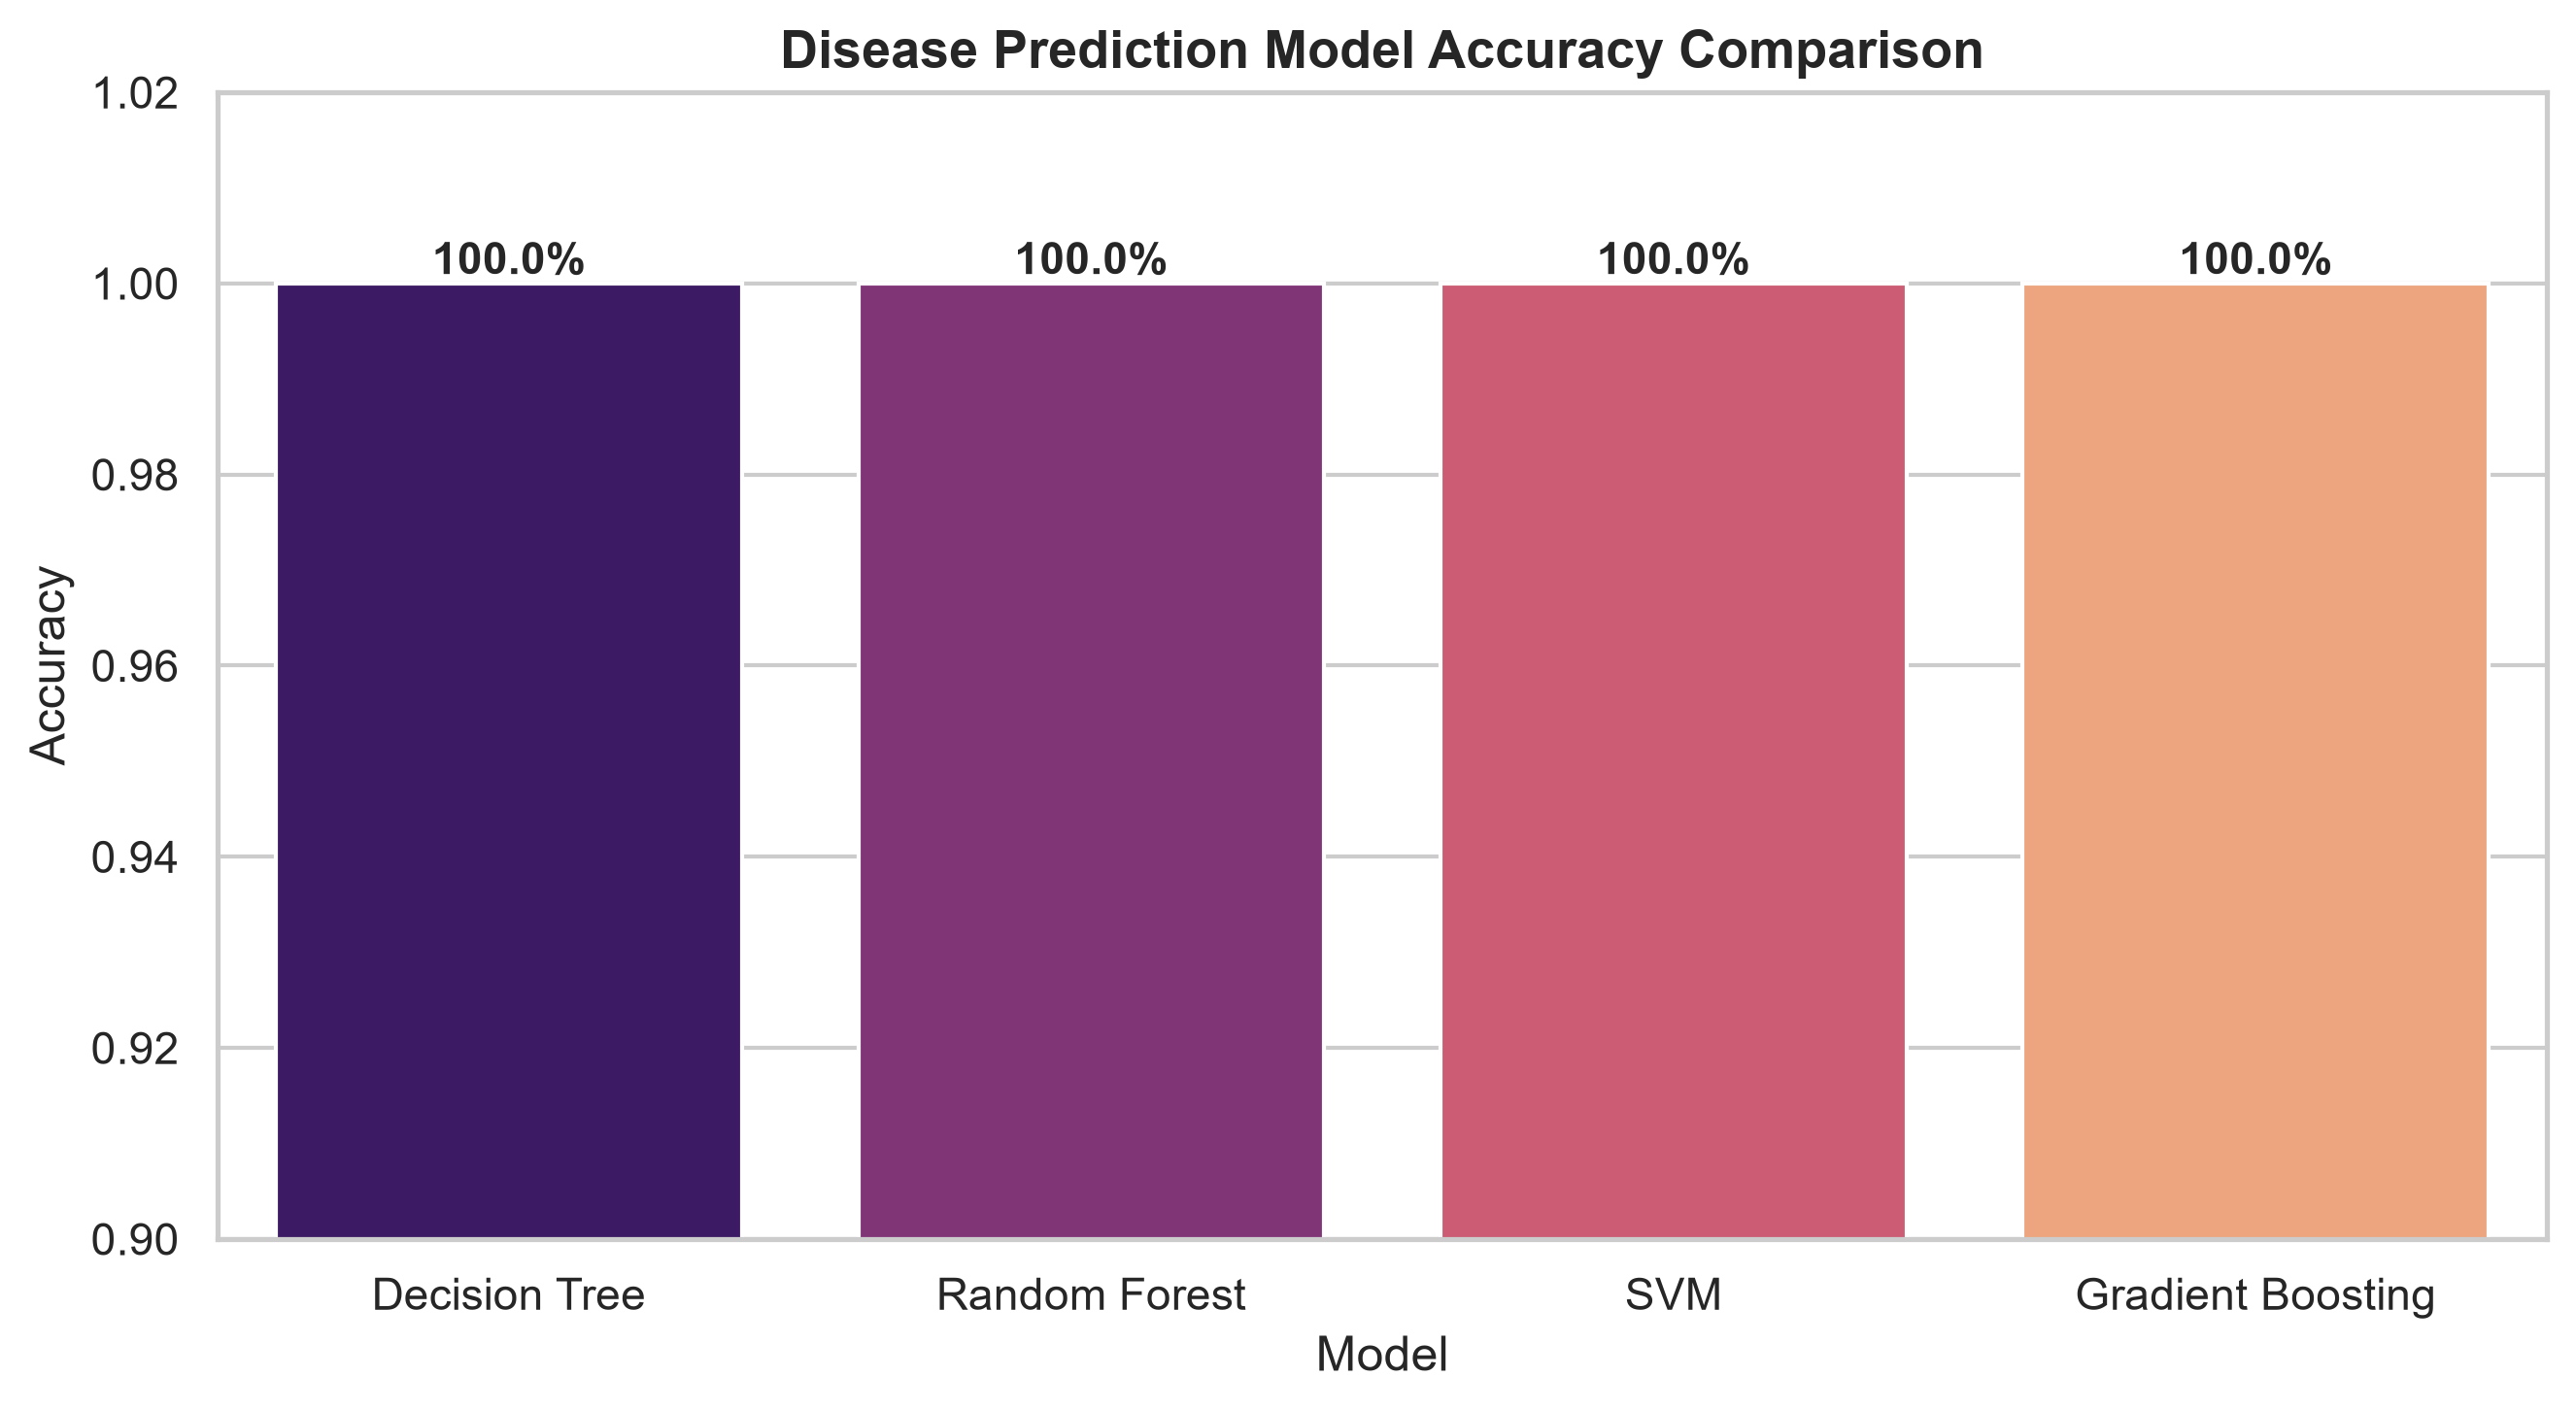

In [23]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(x='Model', y='Accuracy', data=benchmark_df, palette='magma')
plt.title('Disease Prediction Model Accuracy Comparison', fontsize=13, fontweight='bold')
plt.ylim(0.9, 1.02)
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 12. Stratified 5-Fold Cross Validation

In [24]:
cv_scores = cross_val_score(rf_model, X_binary, y, cv=5, scoring='accuracy')
print(f"5-Fold CV Accuracy Scores: {cv_scores}")
print(f"Mean 5-Fold CV Accuracy:   {cv_scores.mean() * 100:.2f}%")

5-Fold CV Accuracy Scores: [1. 1. 1. 1. 1.]
Mean 5-Fold CV Accuracy:   100.00%


### 13. Confusion Matrix Diagnostic Heatmap

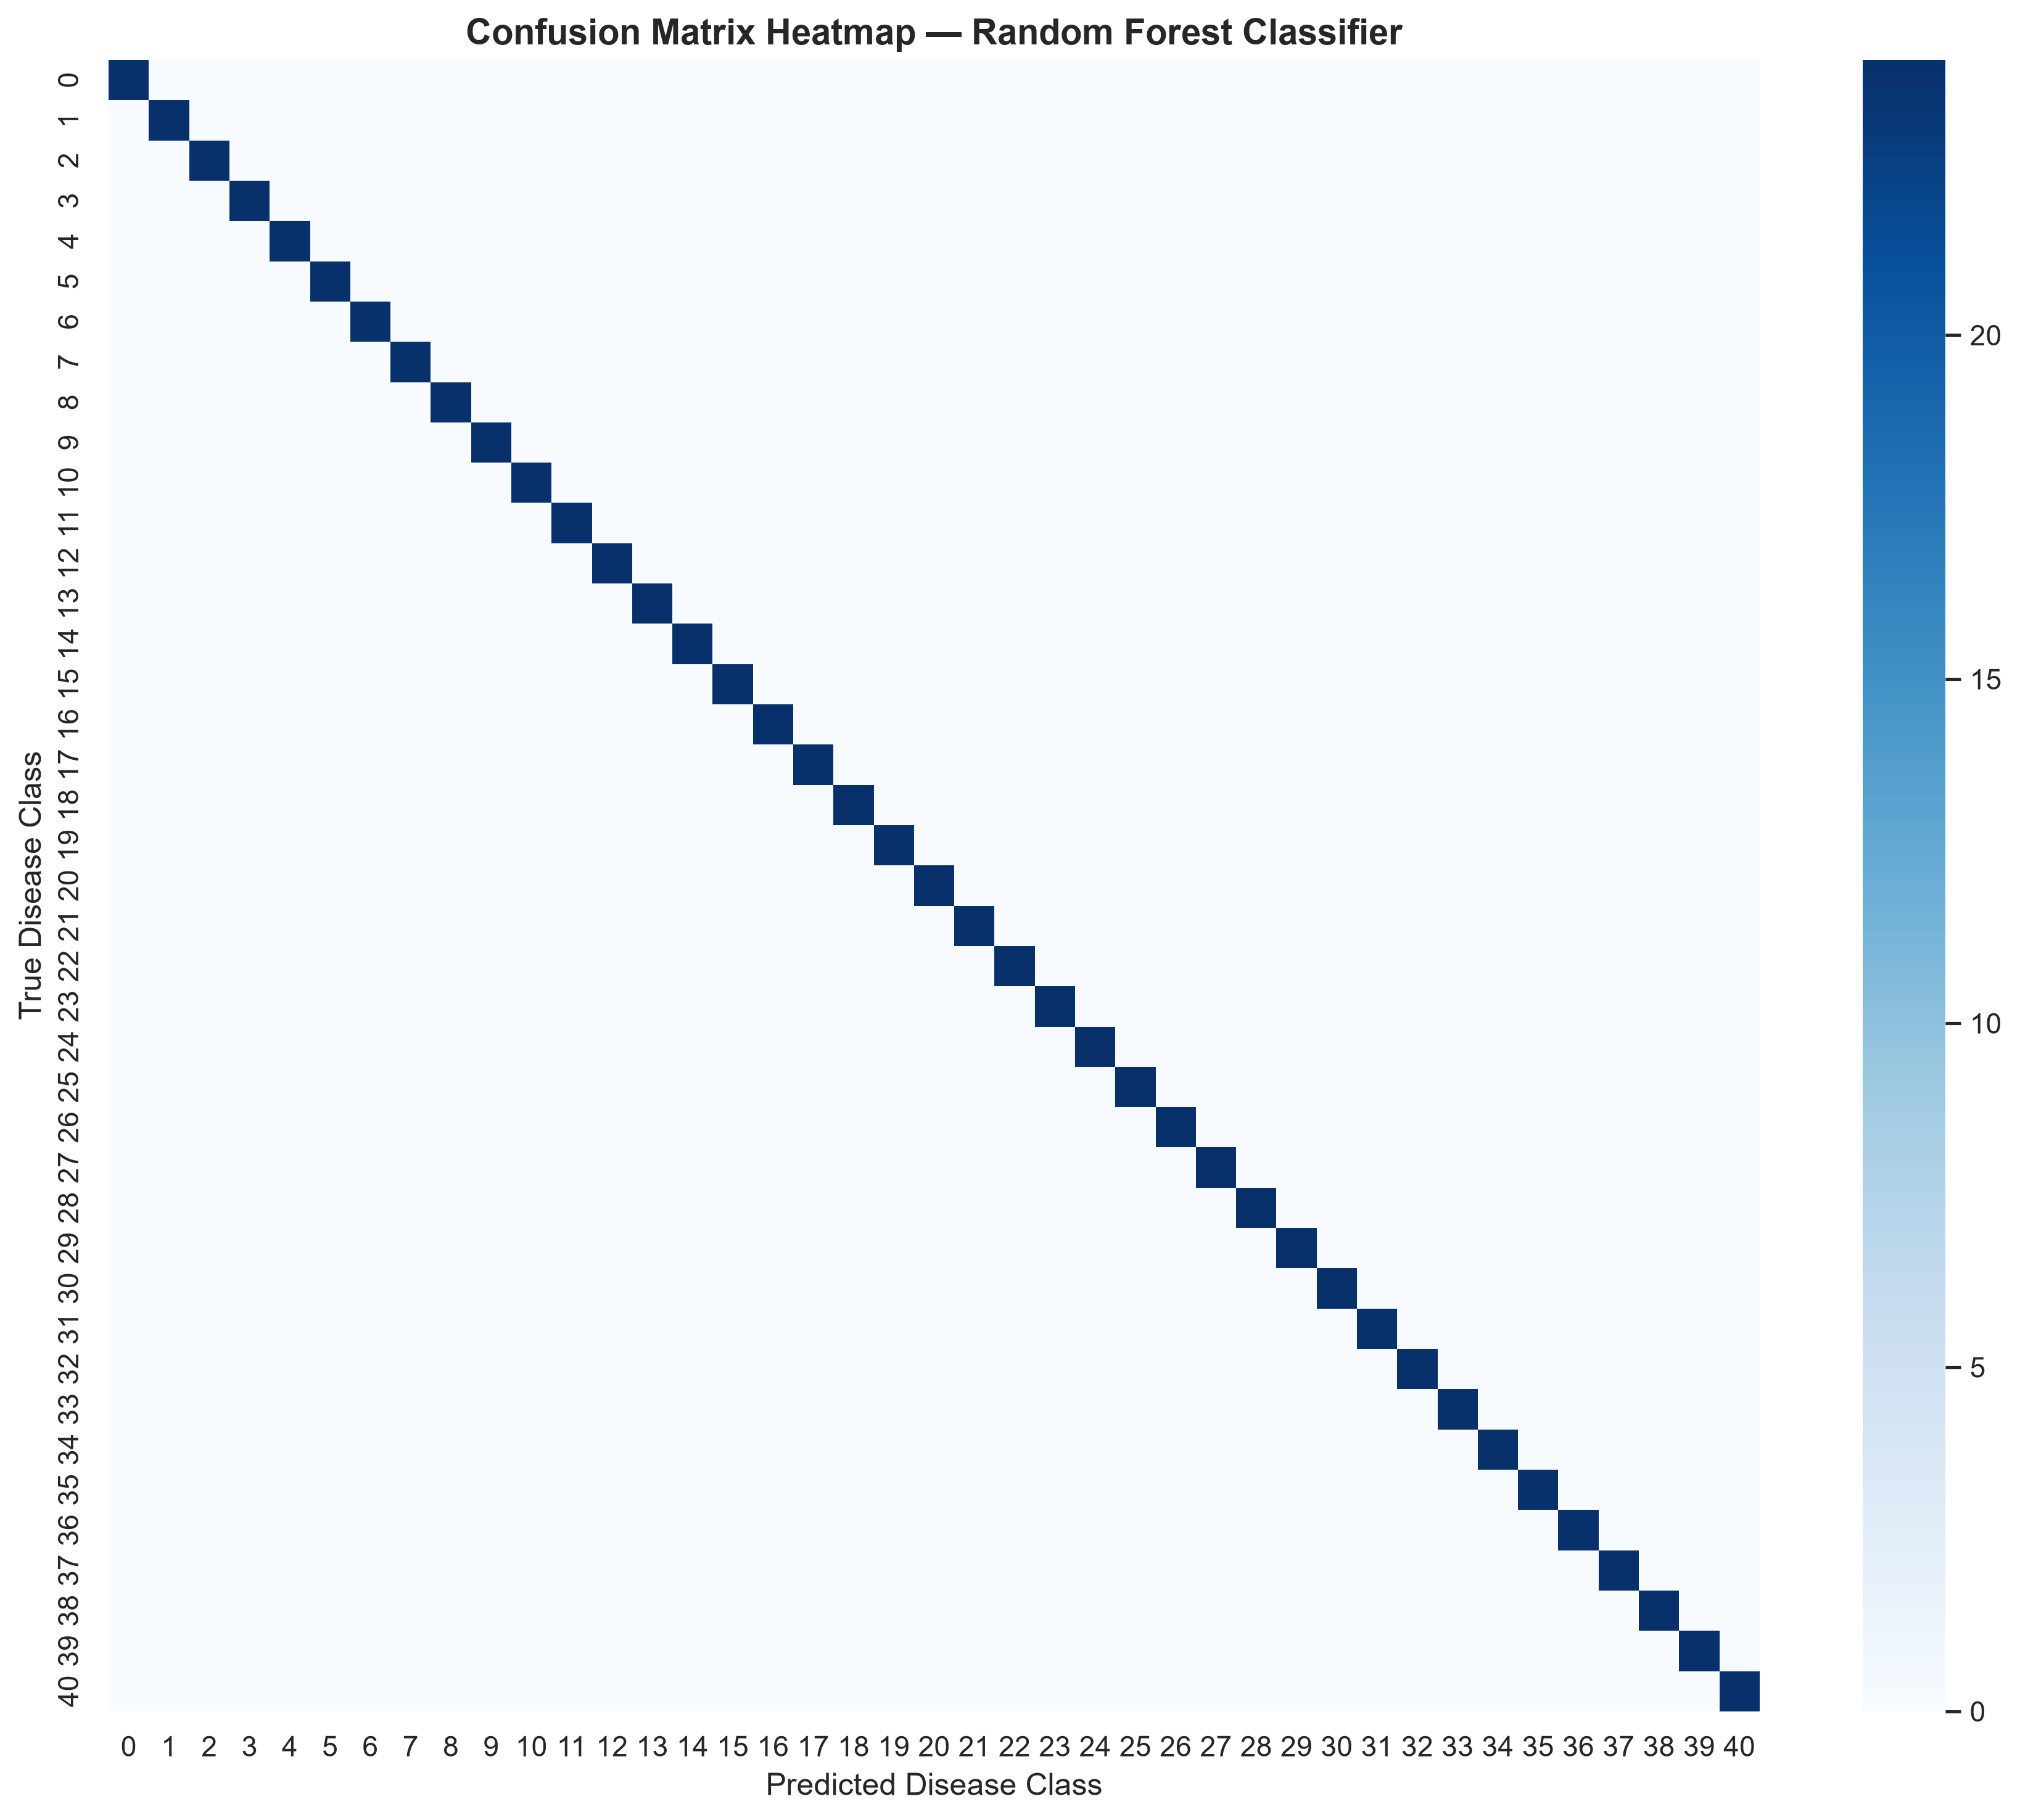

In [25]:
cm = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap='Blues', cbar=True)
plt.title('Confusion Matrix Heatmap — Random Forest Classifier', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Disease Class')
plt.ylabel('True Disease Class')
plt.tight_layout()
plt.show()

### 14. Feature Importance Analysis

In [26]:
importances = pd.Series(rf_model.feature_importances_, index=all_symptoms).sort_values(ascending=False).head(20)

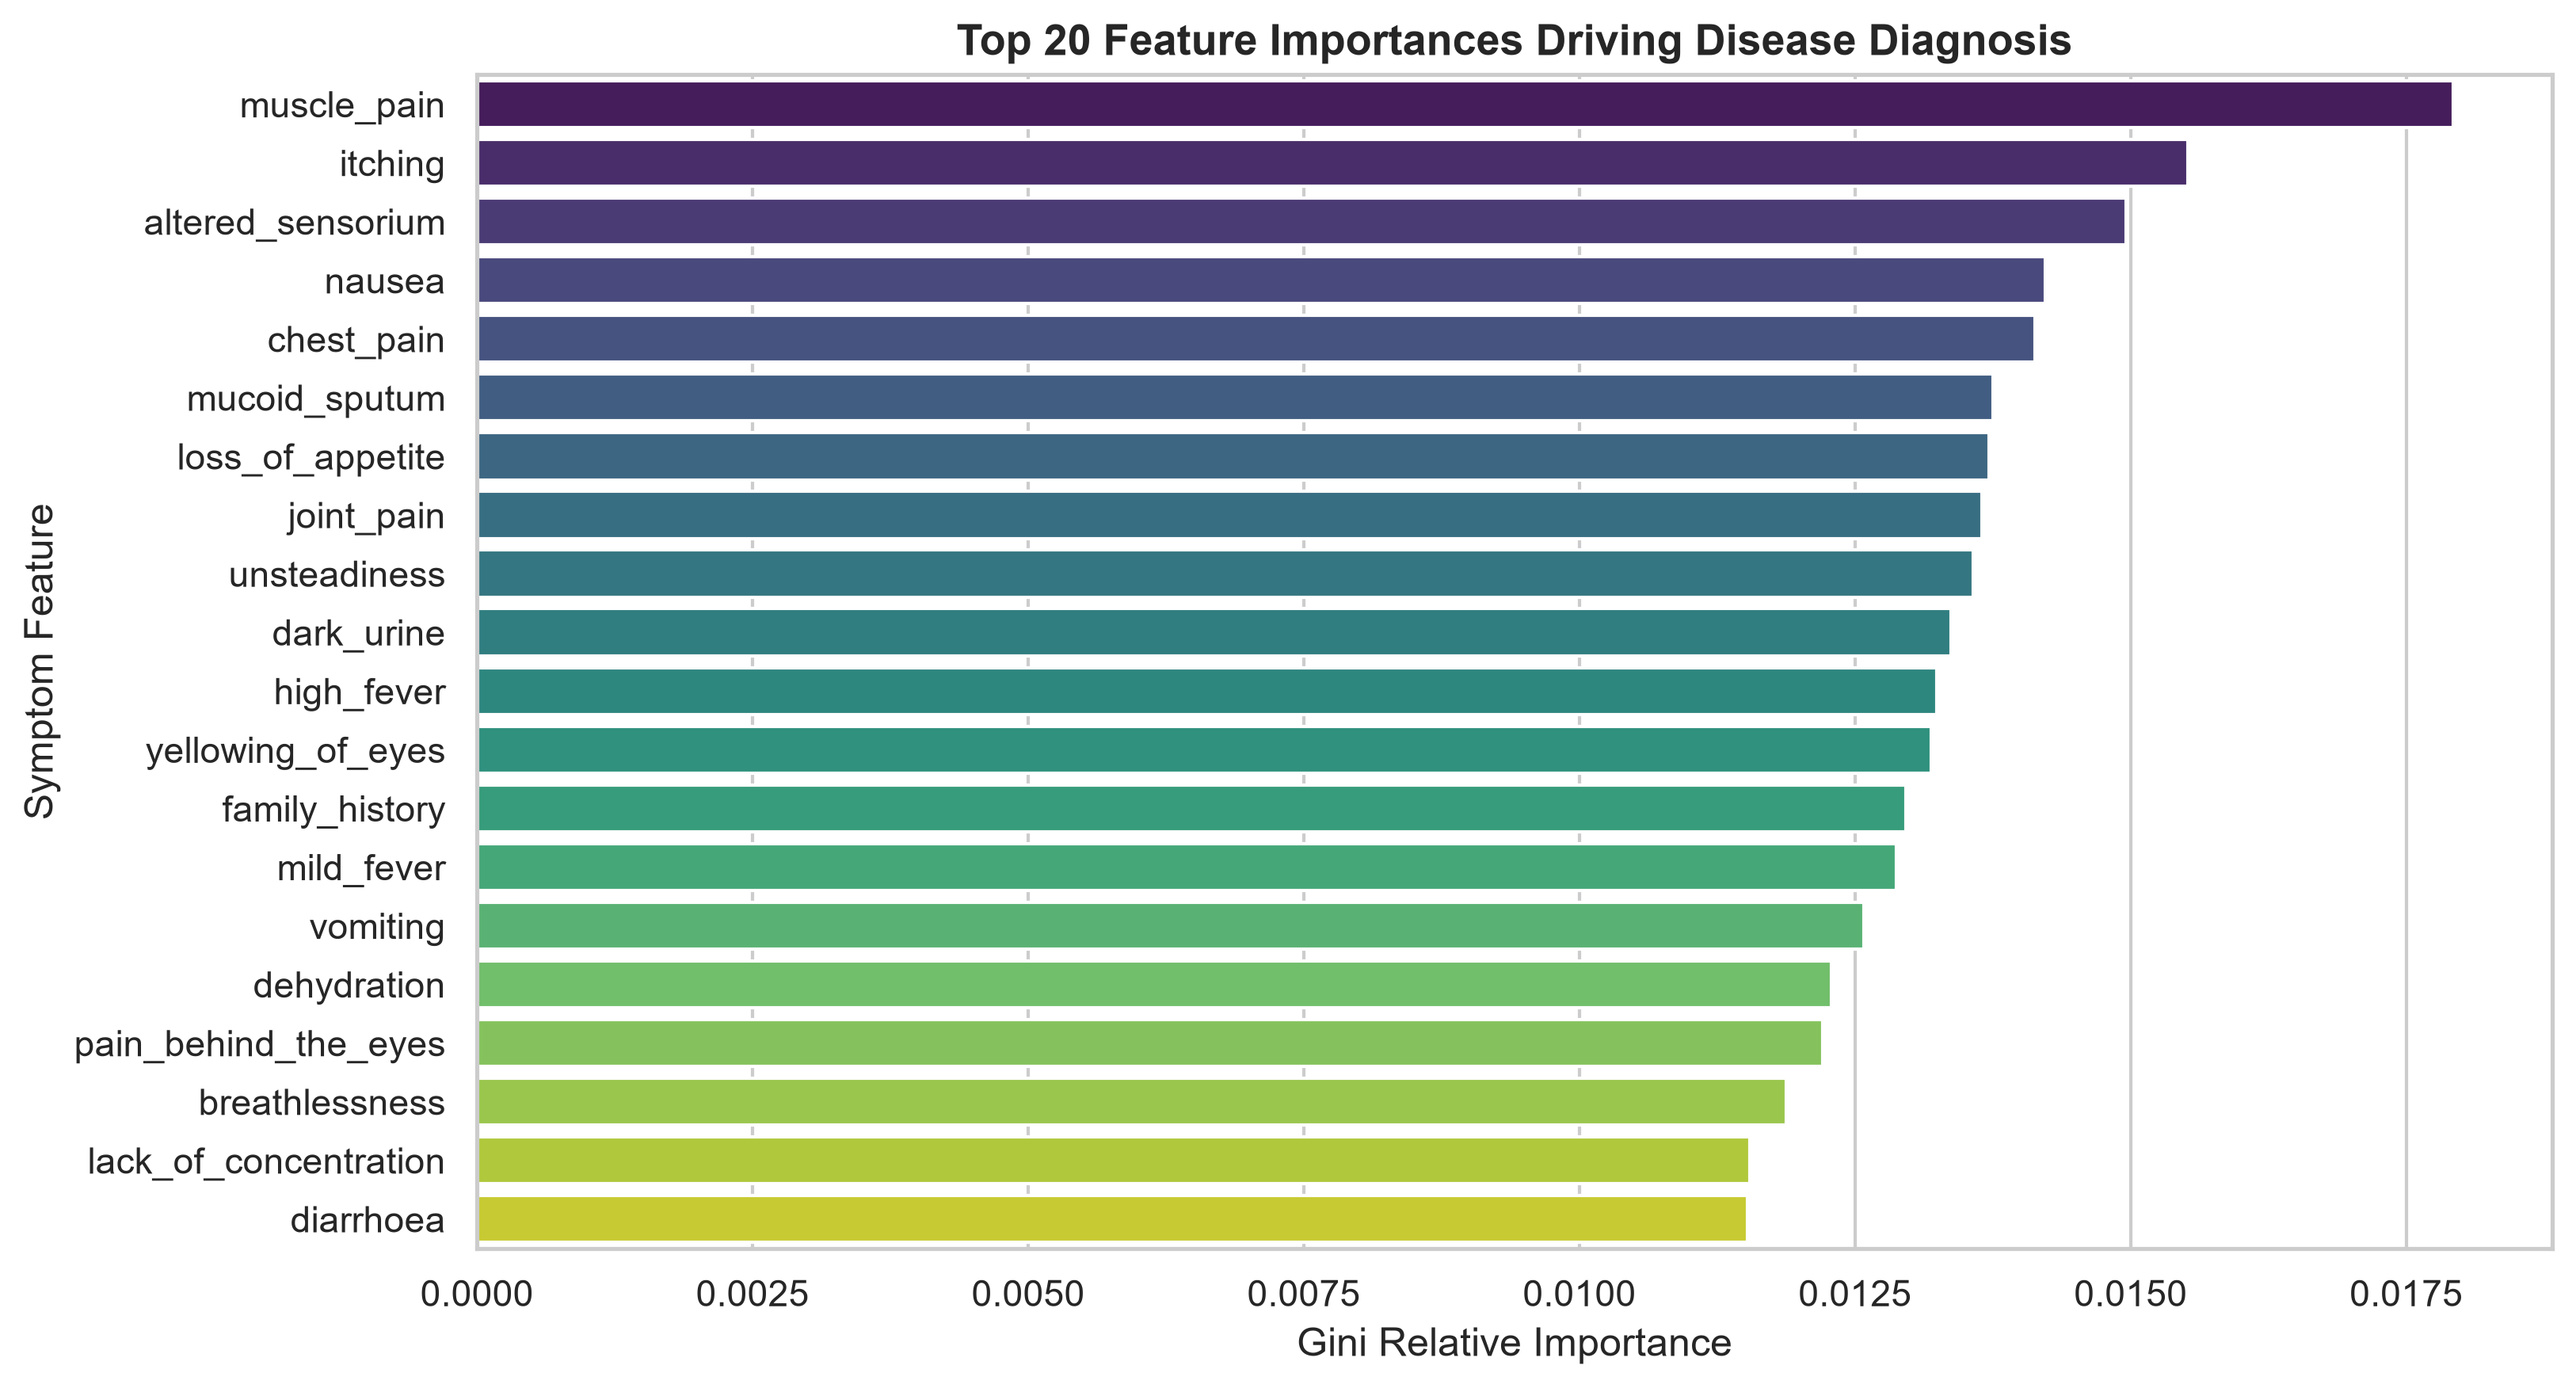

In [27]:
plt.figure(figsize=(11, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Top 20 Feature Importances Driving Disease Diagnosis', fontsize=13, fontweight='bold')
plt.xlabel('Gini Relative Importance')
plt.ylabel('Symptom Feature')
plt.tight_layout()
plt.show()

### 15. Clinical Diagnostic & Precaution Inference Engine

In [28]:
clean_desc = description.copy()
clean_desc['Disease'] = clean_desc['Disease'].str.strip().str.replace(' ', '')
desc_dict = dict(zip(clean_desc['Disease'], clean_desc['Description']))

In [29]:
clean_prec = precaution.copy()
clean_prec['Disease'] = clean_prec['Disease'].str.strip().str.replace(' ', '')
prec_cols = ['Precaution_1', 'Precaution_2', 'Precaution_3', 'Precaution_4']

In [30]:
def predict_disease_and_precautions(input_symptoms):
    cleaned_input = [s.strip().replace(' ', '') for s in input_symptoms]
    input_vector = pd.DataFrame(0, index=[0], columns=all_symptoms)
    for sym in cleaned_input:
        if sym in input_vector.columns:
            input_vector.loc[0, sym] = 1
    pred_disease = rf_model.predict(input_vector)[0]
    disease_desc = desc_dict.get(pred_disease, 'No description available.')
    disease_prec_row = clean_prec[clean_prec['Disease'] == pred_disease]
    precautions_list = []
    if not disease_prec_row.empty:
        precautions_list = disease_prec_row[prec_cols].values.flatten().tolist()
    return {
        'Predicted Disease': pred_disease,
        'Description': disease_desc,
        'Precautions': precautions_list
    }

### 16. Clinical Inference Demonstration

In [31]:
test_symptoms_sample = ['itching', 'skin_rash', 'nodal_skin_eruptions']
result = predict_disease_and_precautions(test_symptoms_sample)

In [32]:
print(f"Input Symptoms:   {test_symptoms_sample}")
print(f"Predicted Diagnosis: {result['Predicted Disease']}")
print(f"Disease Overview:   {result['Description']}")
print(f"Recommended Precautions: {result['Precautions']}")

Input Symptoms:   ['itching', 'skin_rash', 'nodal_skin_eruptions']
Predicted Diagnosis: Fungalinfection
Disease Overview:   In humans, fungal infections occur when an invading fungus takes over an area of the body and is too much for the immune system to handle. Fungi can live in the air, soil, water, and plants. There are also some fungi that live naturally in the human body. Like many microbes, there are helpful fungi and harmful fungi.
Recommended Precautions: ['bath twice', 'use detol or neem in bathing water', 'keep infected area dry', 'use clean cloths']


### 17. Model Artifact Serialization

In [33]:
joblib.dump(rf_model, 'disease_prediction_model.joblib')
print("Random Forest Model saved successfully as disease_prediction_model.joblib")

Random Forest Model saved successfully as disease_prediction_model.joblib
